In [1]:
import numpy as np

In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
mpl.rcParams['animation.embed_limit'] = 100
from IPython.display import HTML

In [3]:
def make_grid(x_min, x_max, y_min, y_max, nx, ny):
    hx = (x_max - x_min) / nx
    hy = (y_max - y_min) / ny

    x = x_min + (np.arange(nx) + 0.5) * hx
    y = y_min + (np.arange(ny) + 0.5) * hy

    X, Y = np.meshgrid(x, y, indexing='ij')
    return X, Y, hx, hy

In [4]:
def plot_field(X, Y, u, title="", cmap="RdBu_r", levels=30, mode="2d"):
    if mode == "2d":
        fig, ax = plt.subplots(figsize=(6, 5), dpi=120)
        cf = ax.contourf(X, Y, u, levels=levels, cmap=cmap)
        fig.colorbar(cf, ax=ax)
        ax.set_aspect('equal')
        ax.set_title(title)
        ax.set_xlabel('x'); ax.set_ylabel('y')
        plt.tight_layout(); plt.show()
    elif mode == "3d":
        fig = plt.figure(figsize=(7, 5), dpi=120)
        ax = fig.add_subplot(projection='3d')
        surf = ax.plot_surface(X, Y, u, cmap=cmap, edgecolor='none',
                               rstride=1, cstride=1, linewidth=0)
        fig.colorbar(surf, ax=ax, shrink=0.6)
        ax.set_title(title)
        ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('u')
        plt.tight_layout(); plt.show()
    else:
        raise ValueError("mode должен быть '2d' или '3d'")


def plot_convergence(history):
    fig, ax = plt.subplots(figsize=(6, 4), dpi=120)
    ax.plot(history, marker='o', markersize=3, linewidth=1)
    ax.set_xlabel('Номер итерации')
    ax.set_ylabel("log10(||r_k|| / ||r_0||)")
    ax.set_title("Сходимость")
    ax.grid(True, which='both', linestyle='--', alpha=0.5)
    ax.set_yscale('log')
    plt.tight_layout()
    plt.show()

In [5]:
def convergence_order(errors, hs):
    errors = np.asarray(errors, dtype=float)
    hs = np.asarray(hs, dtype=float)
    return np.log(errors[:-1] / errors[1:]) / np.log(hs[:-1] / hs[1:])


def plot_convergence_order(errors, hs):
    errors = np.asarray(errors, dtype=float)
    hs = np.asarray(hs, dtype=float)

    fig, ax = plt.subplots(figsize=(6, 5), dpi=120)

    ax.loglog(hs, errors, 'o-', color='black',
              linewidth=1.5, markersize=6, label="Численная погрешность")

    h_ref = np.array([hs.min(), hs.max()])
    for p in (1, 2):
        ref = errors[0] * (h_ref / hs[0])**p
        ax.loglog(h_ref, ref, '--', linewidth=1.0,
                  label=f"$O(h^{p})$")

    ax.set_xlabel("Шаг сетки $h$")
    ax.set_ylabel("Погрешность")
    ax.set_title("Порядок аппроксимации")
    ax.grid(True, which='both', linestyle=':', alpha=0.6)
    ax.legend()
    plt.tight_layout()
    plt.show()

In [6]:
def OpL(u, hx, hy, alpha):
    Lu = np.zeros_like(u)

    Lu[1:-1, :] += (2*u[1:-1, :] - u[:-2, :] - u[2:, :]) / hx**2
    Lu[0,  :]   += (u[0, :]  - u[1, :])  / hx**2
    Lu[-1, :]   += (u[-1, :] - u[-2, :]) / hx**2

    Lu[:, 1:-1] += (2*u[:, 1:-1] - u[:, :-2] - u[:, 2:]) / hy**2
    Lu[:, 0]    += (u[:, 0]  - u[:, 1])  / hy**2
    Lu[:, -1]   += (u[:, -1] - u[:, -2]) / hy**2

    Lu += alpha * u

    return Lu

In [7]:
def optimal_tau(hx, hy, alpha):
    lam_min = alpha
    lam_max = alpha + 4.0/hx**2 + 4.0/hy**2
    return 2.0 / (lam_min + lam_max), lam_min, lam_max

In [8]:
def simple_iteration(OpL, F, tau, tol=1e-8, max_iter=200000):
    u = np.zeros_like(F)
    r = OpL(u) - F
    r0 = np.sqrt(np.sum(r * r))

    for k in range(1, max_iter + 1):
        u -= tau * r
        r = OpL(u) - F
        rel = np.sqrt(np.sum(r * r)) / r0
        yield k, u, r, rel
        if rel < tol:
            return

In [9]:
def solve(OpL, F, X, Y, hx, hy, alpha,
          u_ex=None, tol=1e-8, max_iter=200000, verbose=True,
          save_history=True, snapshot_every=None, label=""):
    tau, lam_min, lam_max = optimal_tau(hx, hy, alpha)

    history = [1.0] if save_history else None
    snapshots, snap_iters = [], []
    if snapshot_every is not None:
        snapshots.append(np.zeros_like(F))
        snap_iters.append(0)

    u = np.zeros_like(F)
    last_k, last_rel = 0, 1.0
    for k, u, r, rel in simple_iteration(OpL, F, tau, tol=tol, max_iter=max_iter):
        last_k, last_rel = k, rel
        if save_history:
            history.append(rel)
        if snapshot_every and k % snapshot_every == 0:
            snapshots.append(u.copy())
            snap_iters.append(k)

    converged = last_rel < tol
    h = max(hx, hy)

    out = {
        "X": X, "Y": Y, "hx": hx, "hy": hy,
        "u": u, "F": F, "h": h,
        "tau": tau, "lam_min": lam_min, "lam_max": lam_max,
        "alpha": alpha,
        "iters": last_k, "converged": converged,
        "hist": np.array(history) if save_history else None,
        "snapshots": snapshots if snapshot_every else None,
        "snap_iters": snap_iters if snapshot_every else None,
    }

    if u_ex is not None:
        err = np.abs(u - u_ex)
        out["u_ex"] = u_ex
        out["err"]  = err
        out["err_L2"]  = np.sqrt(hx*hy*np.sum((u - u_ex)**2))
        out["err_max"] = err.max()

    if verbose:
        msg = f"{label}  n={X.shape[0]}x{X.shape[1]}  h={h:.4f}  iters={last_k}"
        if u_ex is not None:
            msg += f"  ||e||_L2={out['err_L2']:.3e}  max|e|={out['err_max']:.3e}"
        print(msg)

    return out

# Задача 2.15 (пункт а)

## Постановка

Решить задачу Неймана для экранированного уравнения Пуассона
в прямоугольнике:

$$
\begin{cases}
\Delta u - 4u = 12(1 - 2y^2), & -1 < x < 1, \quad -1 < y < 1, \\[4pt]
u_x(-1, y) = 2\sinh 2, & u_x(1, y) = -2\sinh 2, \\[4pt]
u_y(x, -1) = 2\cosh 2 - 12, & u_y(x, 1) = 2\cosh 2 + 12.
\end{cases}
$$

## Точное решение:

$$
u_0(x, y) = -\cosh(2x) + \sinh(2y) + 6y^2.
$$


In [10]:
def RHS_a(X, Y, hx, hy):
    F = (24.0 * Y**2 - 12.0).astype(float)

    F[0,  :] += -2.0 * np.sinh(2.0) / hx
    F[-1, :] += -2.0 * np.sinh(2.0) / hx
    F[:, 0]  += -(2.0 * np.cosh(2.0) - 12.0) / hy
    F[:, -1] +=  (2.0 * np.cosh(2.0) + 12.0) / hy
    return F

In [11]:
def exact_solution(X, Y):
    return -np.cosh(2.0*X) + np.sinh(2.0*Y) + 6.0*Y**2

In [12]:
def solve_a(nx, ny, tol=1e-8, max_iter=200000, verbose=True,
            save_history=True, snapshot_every=None):
    X, Y, hx, hy = make_grid(-1.0, 1.0, -1.0, 1.0, nx, ny)
    alpha = 4.0

    opL  = lambda u: OpL(u, hx, hy, alpha)
    F    = RHS_a(X, Y, hx, hy)
    u_ex = exact_solution(X, Y)

    return solve(opL, F, X, Y, hx, hy, alpha,
                 u_ex=u_ex, tol=tol, max_iter=max_iter,
                 verbose=verbose, save_history=save_history,
                 snapshot_every=snapshot_every, label="(a)")

In [13]:
res = solve_a(50, 50, save_history=True, snapshot_every=20)

(a)  n=50x50  h=0.0400  iters=8589  ||e||_L2=1.026e-03  max|e|=7.517e-04


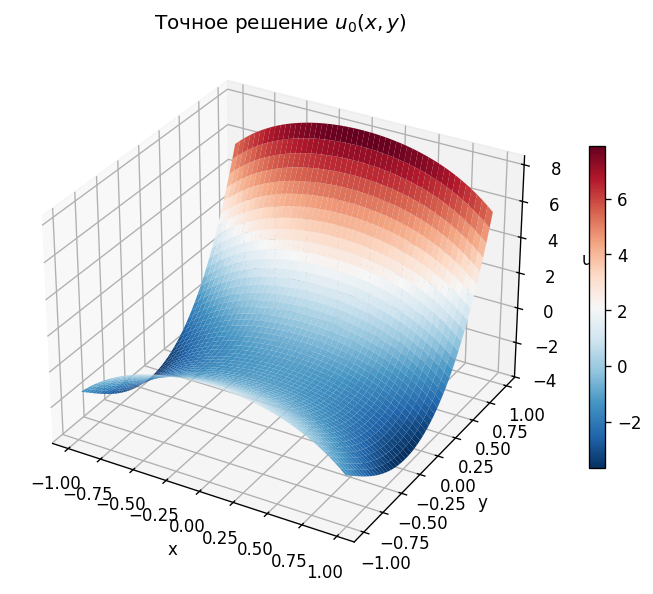

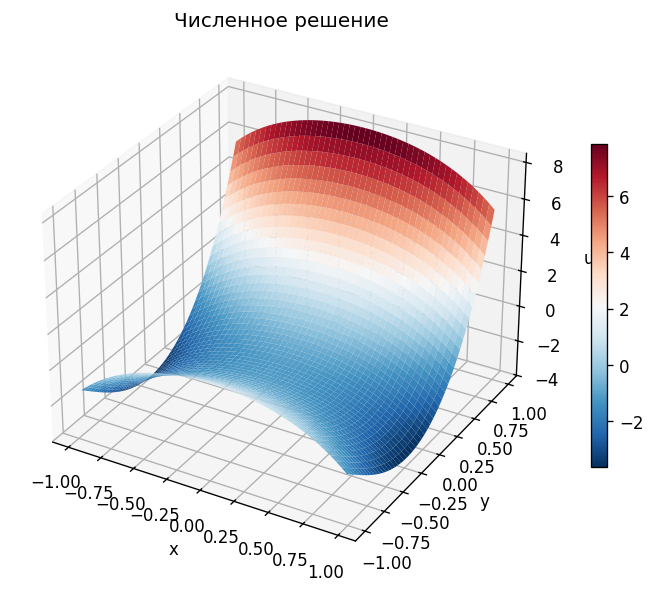

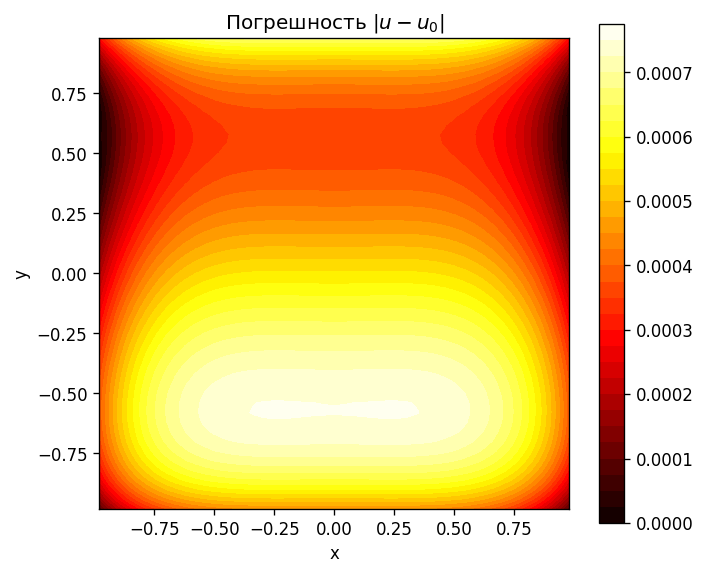

In [14]:
plot_field(res["X"], res["Y"], res["u_ex"],
           title="Точное решение $u_0(x,y)$", mode="3d")

plot_field(res["X"], res["Y"], res["u"],
           title="Численное решение", mode="3d")

plot_field(res["X"], res["Y"], res["err"],
           title="Погрешность $|u - u_0|$", cmap="hot", mode="2d")

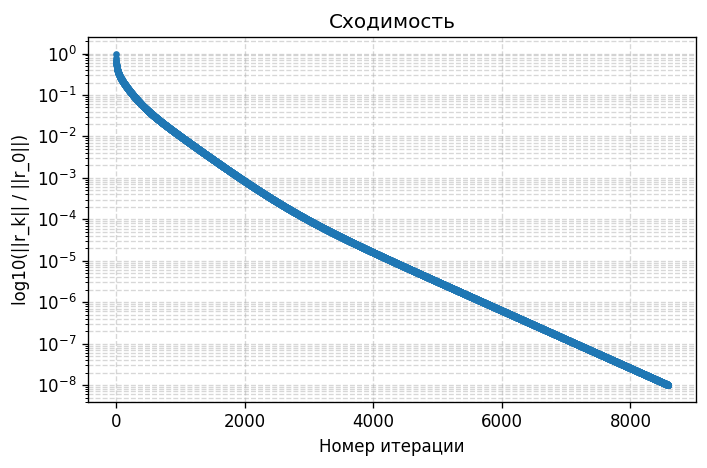

In [15]:
plot_convergence(res["hist"])

(a)  n=20x10  h=0.2000  iters=902  ||e||_L2=9.004e-03  max|e|=8.173e-03
(a)  n=20x20  h=0.1000  iters=1422  ||e||_L2=6.397e-03  max|e|=4.682e-03
(a)  n=20x40  h=0.1000  iters=3480  ||e||_L2=6.184e-03  max|e|=3.764e-03
(a)  n=20x80  h=0.1000  iters=11556  ||e||_L2=6.170e-03  max|e|=3.533e-03

Порядки аппроксимации (L2):  [0.49321373        inf        inf]
Порядки аппроксимации (max): [0.80382275        inf        inf]


/tmp/ipykernel_3814/3177587397.py:4: RuntimeWarning: divide by zero encountered in divide
  return np.log(errors[:-1] / errors[1:]) / np.log(hs[:-1] / hs[1:])


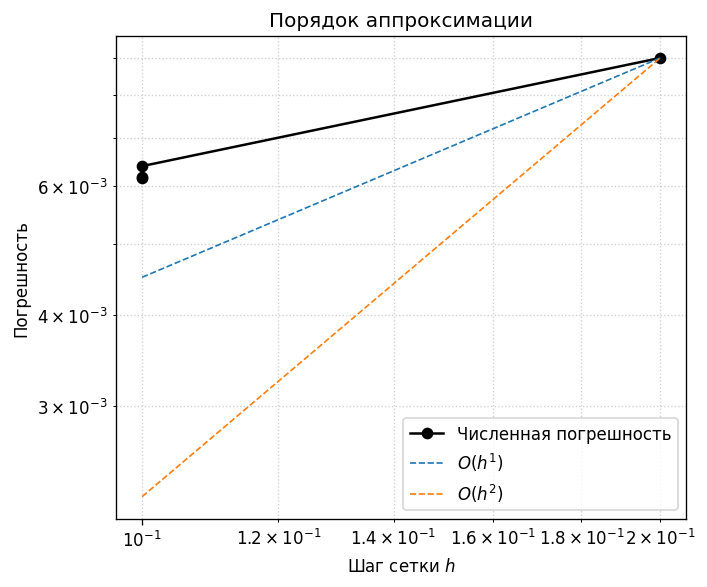

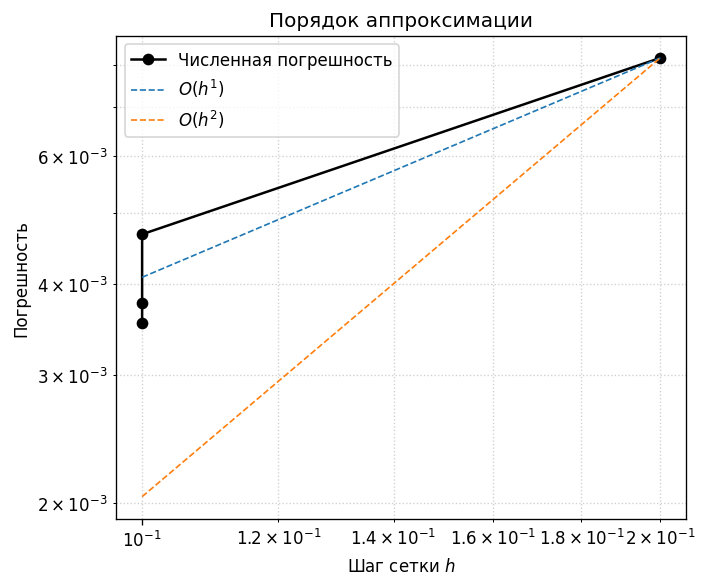

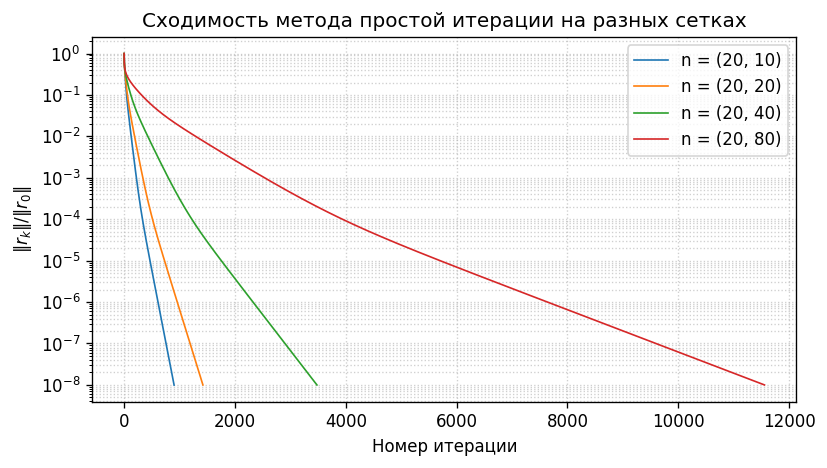

In [28]:
grids = [20, 40, 80, 160]
grids = [(20, 10), (20, 20), (20, 40), (20, 80)]

results = [solve_a(nx=n[0], ny=n[1], save_history=True) for n in grids]

hs       = [r["h"]       for r in results]
errs_L2  = [r["err_L2"]  for r in results]
errs_max = [r["err_max"] for r in results]
hists    = [r["hist"]    for r in results]

print("\nПорядки аппроксимации (L2): ", convergence_order(errs_L2,  hs))
print("Порядки аппроксимации (max):", convergence_order(errs_max, hs))

plot_convergence_order(errs_L2,  hs)
plot_convergence_order(errs_max, hs)

fig, ax = plt.subplots(figsize=(7, 4), dpi=120)
for n, hist in zip(grids, hists):
    ax.semilogy(hist, linewidth=1, label=f"n = {n}")
ax.set_xlabel("Номер итерации")
ax.set_ylabel(r"$\|r_k\| / \|r_0\|$")
ax.set_title("Сходимость метода простой итерации на разных сетках")
ax.grid(True, which='both', linestyle=':', alpha=0.6)
ax.legend()
plt.tight_layout()
plt.show()


In [ ]:
X, Y   = res["X"], res["Y"]
u_ex   = res["u_ex"]
frames = res["snapshots"]
iters  = res["snap_iters"]

max_iter_anim = 2000
keep = [i for i, k in enumerate(iters) if k <= max_iter_anim]
iters  = [iters[i]  for i in keep]
frames = [frames[i] for i in keep]

z_min = min(u_ex.min(), min(f.min() for f in frames))
z_max = max(u_ex.max(), max(f.max() for f in frames))

fig = plt.figure(figsize=(7, 5), dpi=100)
ax  = fig.add_subplot(projection='3d')

def update(i):
    ax.clear()
    ax.plot_surface(X, Y, frames[i], cmap="RdBu_r",
                    edgecolor='none', rstride=1, cstride=1, alpha=0.95)
    ax.plot_wireframe(X[::4, ::4], Y[::4, ::4], u_ex[::4, ::4],
                      color='black', linewidth=0.4, alpha=0.4)
    ax.set_zlim(z_min, z_max)
    ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('u')
    ax.set_title(f"Итерация {iters[i]} "
                 f"(цвет — численное, чёрная сетка — точное)")
    return []

anim = FuncAnimation(fig, update, frames=len(frames),
                     interval=100, blit=False)
plt.close(fig)
HTML(anim.to_jshtml())

# Задача 2.15 (пункт б)

## Постановка

Прямоугольный пружинный матрас, пружины распределены равномерно
с жёсткостью $k$, полотно имеет натяжение $T$. На матрас кладут
тонкое тяжёлое кольцо массы $M$ радиуса $R$ с центром в точке
$(x_0, y_0)$. Найти прогиб матраса $u(x, y)$:

$$
\begin{cases}
-T\,\Delta u + k\,u = f(x, y), & 0 < x < L_x, \quad 0 < y < L_y, \\[4pt]
u_x(0, y) = 0, & u_x(L_x, y) = 0, \\[4pt]
u_y(x, 0) = 0, & u_y(x, L_y) = 0,
\end{cases}
$$

где нагрузка от кольца:

$$
f(x, y) = \frac{Mg}{2\pi R}\,\delta\!\left(\rho - R\right),
\qquad
\rho = \sqrt{(x - x_0)^2 + (y - y_0)^2}.
$$

## Регуляризация дельта-функции:

$$
f_\sigma(x, y) = C_\sigma \exp\!\left(-\frac{(\rho - R)^2}{2\sigma^2}\right),
\qquad
C_\sigma = \frac{Mg}{\displaystyle\iint_\Omega
   \exp\!\left(-\frac{(\rho - R)^2}{2\sigma^2}\right) dS}.
$$

In [18]:
def plot_mattress(res, z_scale=1.0, elev=25, azim=-60,
                  title="", cmap="RdBu_r", flip=True):
    X, Y, u = res["X"], res["Y"], res["u"]
    if flip:
        u = -u
    u_max = np.abs(u).max() or 1.0

    fig = plt.figure(figsize=(8, 5), dpi=120)
    ax  = fig.add_subplot(projection='3d')

    ax.plot_surface(X, Y, np.zeros_like(u),
                    color='lightgray', alpha=0.25,
                    rstride=2, cstride=2, linewidth=0)

    surf = ax.plot_surface(X, Y, u * z_scale,
                           cmap=cmap, edgecolor='none',
                           rstride=1, cstride=1, alpha=0.95)
    fig.colorbar(surf, ax=ax, shrink=0.55, pad=0.1,
                 label=f"$u \\cdot {z_scale:.2f}$")

    ax.set_box_aspect((X.max() - X.min(),
                       Y.max() - Y.min(),
                       2.5 * u_max * z_scale))
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel("$x$"); ax.set_ylabel("$y$"); ax.set_zlabel("прогиб")
    ax.set_title(title or "Поверхность матраса")
    plt.tight_layout()
    plt.show()

In [19]:
def RHS_b(X, Y, hx, hy, M=1.0, R=0.3,
          x0=None, y0=None, sigma=0.05,
          g=9.81, T=1.0):
    if x0 is None:
        x0 = 0.5 * (X.min() + X.max())
    if y0 is None:
        y0 = 0.5 * (Y.min() + Y.max())

    rho    = np.sqrt((X - x0)**2 + (Y - y0)**2)
    kernel = np.exp(-(rho - R)**2 / (2.0 * sigma**2))

    total = M * g / T
    norm = hx * hy * np.sum(kernel)
    F     = total * kernel / norm
    return F

In [20]:
def solve_b(nx, ny,
            M=1.0, R=0.3, x0=None, y0=None,
            sigma=None, g=9.81, T=1.0, k=4.0,
            Lx=2.0, Ly=1.0,
            tol=1e-8, max_iter=200000, verbose=True,
            save_history=True, snapshot_every=None):
    X, Y, hx, hy = make_grid(0.0, Lx, 0.0, Ly, nx, ny)

    if sigma is None:
        sigma = 2.0 * max(hx, hy)

    alpha = k / T

    opL = lambda u: OpL(u, hx, hy, alpha)
    F   = RHS_b(X, Y, hx, hy, M=M, R=R, x0=x0, y0=y0,
                sigma=sigma, g=g, T=T)

    return solve(opL, F, X, Y, hx, hy, alpha,
                 u_ex=None, tol=tol, max_iter=max_iter,
                 verbose=verbose, save_history=save_history,
                 snapshot_every=snapshot_every, label="(b)")

In [21]:
res_b = solve_b(nx=100, ny=100, M=1.0, R=0.3,
                save_history=True, snapshot_every=20)

(b)  n=100x100  h=0.0200  iters=108849


In [22]:
mass_num = res_b["hx"] * res_b["hy"] * np.sum(res_b["F"])
mass_exp = 1.0 * 9.81 / 1.0
print(f"Масса (числ.) = {mass_num:.4e}  ожидается = {mass_exp:.4e}")

Масса (числ.) = 9.8100e+00  ожидается = 9.8100e+00


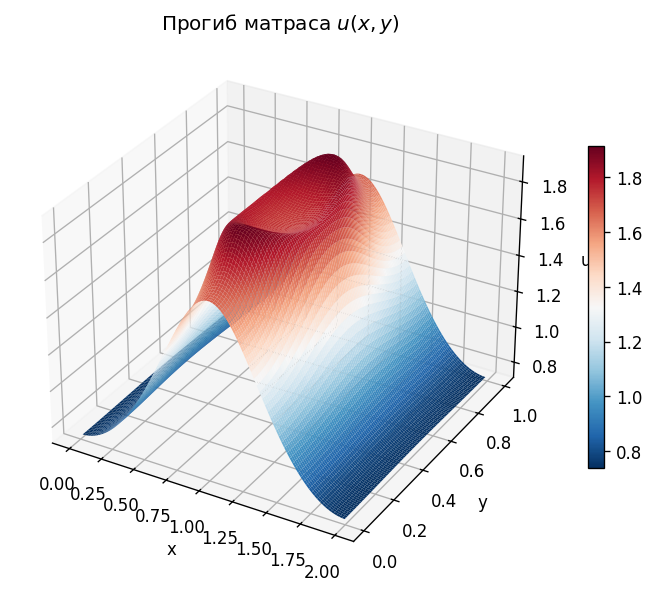

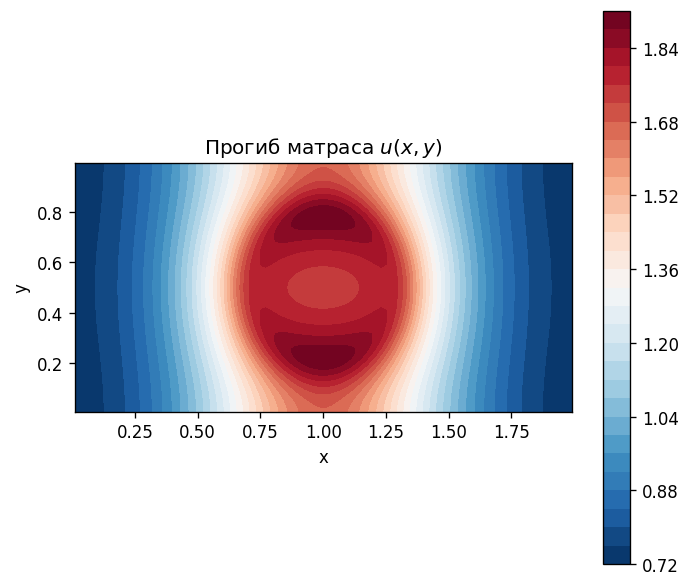

In [23]:
plot_field(res_b["X"], res_b["Y"], res_b["u"],
           title="Прогиб матраса $u(x,y)$", mode="3d")

plot_field(res_b["X"], res_b["Y"], res_b["u"],
           title="Прогиб матраса $u(x,y)$", mode="2d")

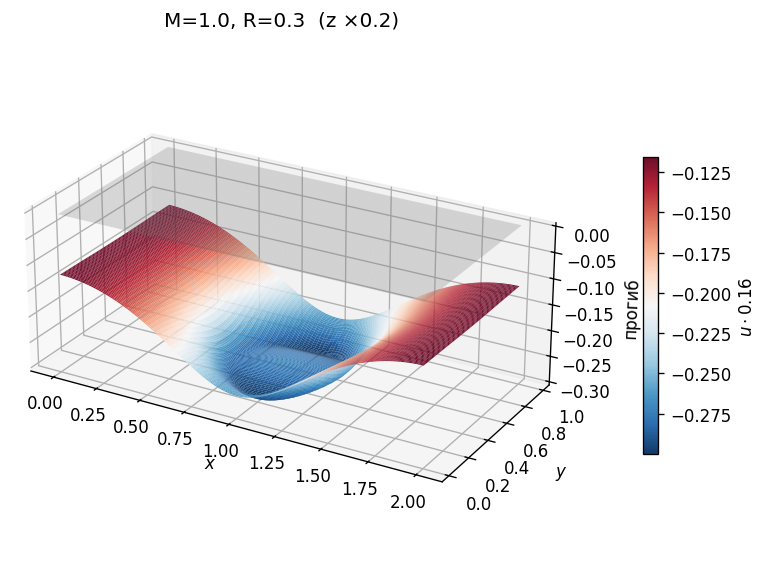

In [24]:
u_max = np.abs(res_b["u"]).max()
z_scale = 0.3 / u_max

plot_mattress(res_b, z_scale=z_scale,
              title=f"M=1.0, R=0.3  (z ×{z_scale:.1f})")

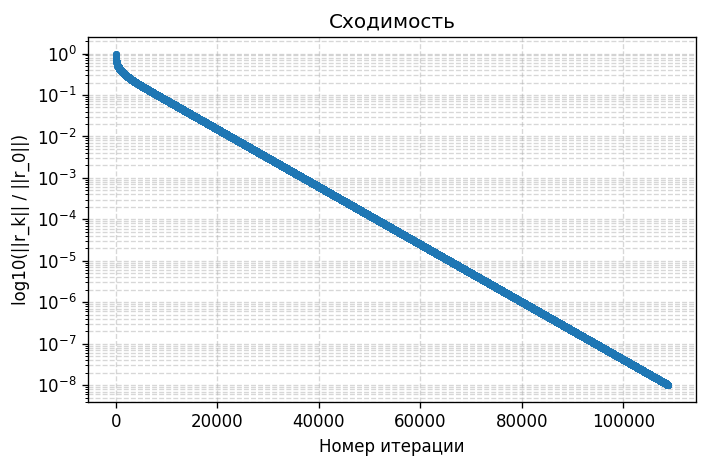

In [25]:
plot_convergence(res_b["hist"])

(b)  n=200x200  h=0.0100  iters=44599


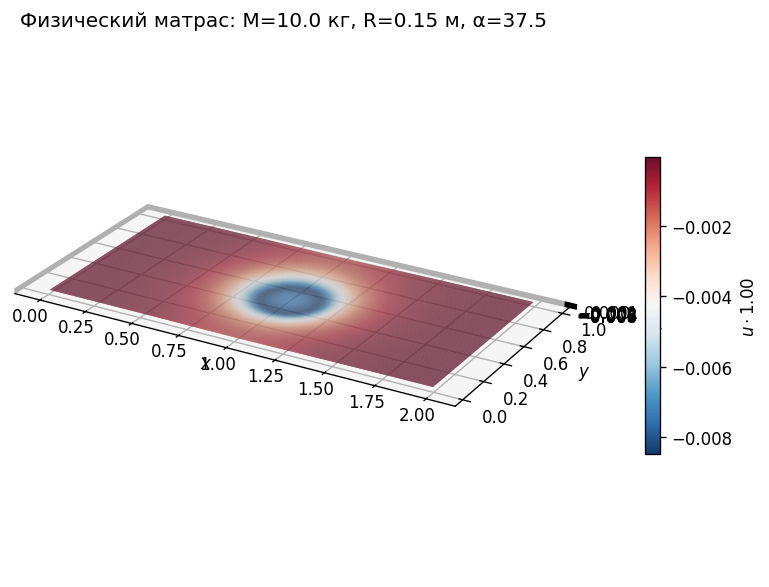

In [26]:
M = 10.0          # кг
R = 0.15          # м
k = 37_500        # Н/м^3
T = 1000          # Н/м
Lx, Ly = 2.0, 1.0

res = solve_b(
    nx=200, ny=200,
    M=M, R=R,
    k=k, T=T,
    Lx=Lx, Ly=Ly,
    sigma=None,
    save_history=True,
    snapshot_every=2,
)

u_max = np.abs(res["u"]).max()
plot_mattress(res, z_scale=1,#0.25 / u_max,
              title=f"Физический матрас: M={M} кг, R={R} м, α={k/T:.1f}")


X, Y   = res["X"], res["Y"]
frames = res["snapshots"]
iters  = res["snap_iters"]

max_iter_anim = 75
keep = [i for i, k in enumerate(iters) if k <= max_iter_anim]
iters  = [iters[i]  for i in keep]
frames = [frames[i] for i in keep]

flip    = True
z_scale = 1.0

u_all = [(-f if flip else f) for f in frames]

z_abs_max = max(np.abs(u).max() for u in u_all) or 1.0
z_lim     = z_abs_max * z_scale * 1.1

fig = plt.figure(figsize=(8, 5), dpi=100)
ax  = fig.add_subplot(projection='3d')

def update(i):
    ax.clear()
    u = u_all[i] * z_scale

    ax.plot_surface(X, Y, np.zeros_like(u),
                    color='lightgray', alpha=0.2,
                    rstride=5, cstride=5, linewidth=0)

    ax.plot_surface(X, Y, u, cmap="RdBu_r",
                    edgecolor='none',
                    rstride=1, cstride=1, alpha=0.95)

    ax.set_zlim(-z_lim, z_lim)
    ax.set_box_aspect((X.max() - X.min(),
                       Y.max() - Y.min(),
                       2.0 * z_lim))
    ax.view_init(elev=25, azim=-60)
    ax.set_xlabel("$x$"); ax.set_ylabel("$y$"); ax.set_zlabel("прогиб")
    ax.set_title(f"Продавливание матраса, итерация {iters[i]}  "
                 f"(z ×{z_scale:.3g})")
    return []

anim = FuncAnimation(fig, update, frames=len(u_all),
                     interval=80, blit=False)
plt.close(fig)
HTML(anim.to_jshtml())